# Best methods: held-out test sets with nested 5-fold CV

All the strongest methods from `dose_trajectory_walkthrough.ipynb` and `original_model_alternatives.ipynb`, scored the same way.

**Protocol (20 seeds).** For each seed:
1. 20% of each class's compounds, and at least one, are held out as the **test set**: 19 of the 86 labelled compounds, covering all 15 classes. The draw changes with the seed.
2. The remaining 67 compounds (train + validation) get a **5-fold compound-stratified CV**. Its out-of-fold predictions choose each method's mixing weights.
3. The base models are refit on all ~68 compounds, combined with the chosen knobs, and scored on the held-out compounds.

The test compounds take no part in any fitting or tuning step. Reported values are mean ± SD over the 20 seeds.

**Hard-weighted macro-F1.** This is the macro-F1 with the hard classes PI3K, PARP, JAK, RAF and AKT counted twice (weight `HARD_WEIGHT = 2`, all other classes 1). With 5 of 15 classes doubled, the hard classes make up half of the score, against a third in the plain macro-F1. It is reported right after macro-F1 everywhere. The weights are still tuned on plain macro-F1.

**Confidence.**
- *Paired compound bootstrap.* The held-out compounds are resampled with replacement within each class (2000×), and macro-F1 is recomputed on their held-out predictions pooled over the 20 seeds. This gives a 95% CI per method. Using the same resamples for every method gives a CI on the gain over the reference.
- *Calibration.* Log-loss, expected calibration error (ECE), and a reliability diagram of the top-class probability.

| method | what it is | knobs tuned in the inner CV |
|---|---|---|
| original | cosine centroid + cosine 7-NN + logistic regression on rows ≥ 0.37 µM, averaged per compound | — |
| RF | random forest (500 trees, `min_samples_leaf=24`) on the same rows | — |
| trajectory | the same three-model ensemble on per-compound 6-dose trajectories of 64 PCA modules | — |
| original + RF | `(1-w)·original + w·RF` | w |
| original + trajectory | `(1-w)·original + w·trajectory` (the walkthrough blend, **reference**) | w |
| (original + RF) + trajectory | `(1-w)·[(1-w_rf)·original + w_rf·RF] + w·trajectory` | w_rf, w |

Left out:
- LightGBM, the PARP/RAF evidence terms and prior correction, each of which was within noise of a simpler method here.
- The CDK-gate rules (Strategy 3 and the greedy gates). They were designed by reading the confusion matrices of these same 86 compounds. In an earlier version of this notebook the gate added nothing on held-out compounds: Strategy 3 was +0.004 vs its blend, and the gated RF blend scored 0.749 vs 0.745 for plain original + RF.

In [1]:
import os; os.environ.update(OMP_NUM_THREADS="1", PYTHONWARNINGS="ignore")
import warnings; warnings.filterwarnings("ignore")
from itertools import product
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from joblib import Parallel, delayed
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

ROOT = Path(".") if Path("X_train.csv.gz").exists() else Path("..")
OUT, FIG = ROOT / "results" / "best_methods", ROOT / "figures"; OUT.mkdir(parents=True, exist_ok=True)
SEEDS, FOLDS, TEST_SIZE, N_BOOT = list(range(20)), 5, 0.2, 2000
CONTROL, UN_CONTROL = "BRD-K60230970", "BRD-K50691590"     # plate controls in train / unlabeled
LD = np.log10([0.04, 0.12, 0.37, 1.11, 3.33, 10.0])

## 1. Data and label-free preprocessing
Same preprocessing as the walkthrough:
- plate-median centering, with medians taken over unlabeled, train and test rows;
- the 80% of genes with the lowest plate R² in the unlabeled data;
- 64 PCA modules fitted on the unlabeled data, then turned into per-compound dose trajectories.

None of these steps uses labels.

In [2]:
read = lambda f: pd.read_csv(ROOT / f, index_col=0)
classes = [l.strip() for l in open(ROOT / "classes.txt") if l.strip()]; K = len(classes)
Xtr, Xte, Xun = read("X_train.csv.gz"), read("X_test.csv.gz"), read("X_unlabeled.csv.gz")
meta = read("meta_train.csv").loc[Xtr.index]
y_row = read("y_train.csv").moa.loc[Xtr.index].map(classes.index).values
Xun = Xun[Xun.pop("compound").ne(UN_CONTROL).values].drop(columns="dose_um")
cmp, dose = meta.compound.values, meta.dose_um.values
ctrl = cmp == CONTROL

plate = lambda X: X.index.str.split(":").str[0]
pool = pd.concat([Xun, Xtr[~ctrl], Xte])
med = pool.groupby(plate(pool)).median()
center = lambda X: X.values - med.loc[plate(X)].values
r2 = ((Xun.groupby(plate(Xun)).transform("mean") - Xun.mean()) ** 2).sum() / ((Xun - Xun.mean()) ** 2).sum()
genes = (r2 <= r2.quantile(0.8)).values
x, x_un = center(Xtr)[:, genes], center(Xun)[:, genes]

scaler = StandardScaler().fit(x_un)
pca = PCA(64, svd_solver="randomized", random_state=2026).fit(scaler.transform(x_un))
modules = pca.transform(scaler.transform(x))

def trajectory_features(S, d):
    o = np.argsort(d); T = np.column_stack([np.interp(LD, np.log10(d[o]), s) for s in S[o].T])   # 6 doses x 64 modules
    peak, span, cd = T[np.abs(T).argmax(0), np.arange(T.shape[1])], LD[-1] - LD[0], LD - LD.mean()
    onset = (LD[(np.abs(T) >= 0.5 * np.abs(peak)).argmax(0)] - LD[0]) / span
    return np.r_[T.T.ravel(), peak, np.trapezoid(T, LD, axis=0) / span, cd @ T / (cd ** 2).sum(), onset, T[-1] - T[-2], T[-1] - peak]

names = np.unique(cmp[~ctrl])
y = np.array([y_row[cmp == c][0] for c in names])
F = np.stack([trajectory_features(modules[cmp == c], dose[cmp == c]) for c in names])
print(f"{len(names)} compounds, {genes.sum()} genes, trajectory features {F.shape[1]}")

86 compounds, 782 genes, trajectory features 768


## 2. Base models
`base_models(fit, pred)` fits the three base models on the `fit` compounds and returns class probabilities for the `pred` compounds. It is the only place where labels are used. The plate-control rows are always in the fit set, with the walkthrough's down-weighting.

In [3]:
unit = lambda v: v / (np.linalg.norm(v, axis=1, keepdims=True) + 1e-9)
def softmax(s): e = np.exp((s - s.max(1, keepdims=True)) / 0.1); return e / e.sum(1, keepdims=True)
proba = lambda m, X: pd.DataFrame(m.predict_proba(X), columns=m.classes_).reindex(columns=range(K), fill_value=0).values

def centroid(Xf, yf, w, Xp):
    u = unit(Xf)
    return softmax(unit(Xp) @ unit(np.stack([np.average(u[yf == c], 0, w[yf == c]) for c in range(K)])).T)

def knn(Xf, yf, w, Xp, k=7):
    S = unit(Xp) @ unit(Xf).T; nn = np.argsort(-S, 1)[:, :k]; P = np.zeros((len(Xp), K))
    np.add.at(P, (np.arange(len(Xp))[:, None], yf[nn]), np.exp(np.take_along_axis(S, nn, 1) / 0.1) * w[nn])
    return P / P.sum(1, keepdims=True)

def logreg(Xf, yf, w, Xp):
    s = StandardScaler().fit(Xf)
    return proba(LogisticRegression(C=0.05, max_iter=3000, random_state=2026).fit(s.transform(Xf), yf, sample_weight=w), s.transform(Xp))

def ensemble(*a): return (centroid(*a) + knn(*a) + logreg(*a)) / 3
def rf(Xf, yf, w, Xp): return proba(RandomForestClassifier(500, min_samples_leaf=24, n_jobs=1, random_state=2026).fit(Xf, yf, sample_weight=w), Xp)
def trajectory(Ff, yf, w, Fp): s = StandardScaler().fit(Ff); return ensemble(s.transform(Ff), yf, w, s.transform(Fp))

def balanced(yf, is_ctrl):
    w = np.where(is_ctrl, (~ctrl).sum() / len(names) / max(is_ctrl.sum(), 1), 1.0)
    for c in np.unique(yf): w[yf == c] /= w[yf == c].sum()
    return w * len(w) / w.sum()

def base_models(fit, pred):
    fr = (np.isin(cmp, names[fit]) & (dose >= 0.37)) | ctrl
    pr = np.isin(cmp, names[pred]) & (dose >= 0.37)
    args = (x[fr], y_row[fr], balanced(y_row[fr], ctrl[fr]), x[pr])
    per_compound = lambda P: (M := pd.DataFrame(P).groupby(cmp[pr]).mean().loc[names[pred]].values) / M.sum(1, keepdims=True)
    return {"original": per_compound(ensemble(*args)), "rf": per_compound(rf(*args)),
            "trajectory": trajectory(F[fit], y[fit], balanced(y[fit], np.zeros(len(fit), bool)), F[pred])}

## 3. 20 seeds × (held-out test + inner 5-fold CV)
Each seed runs on its own worker and takes about a minute.

In [4]:
def run_seed(seed):
    rng = np.random.default_rng(seed)        # per class: 20% of compounds, at least 1, so every class is tested
    test = np.concatenate([rng.choice(np.flatnonzero(y == c), max(1, round(TEST_SIZE * (y == c).sum())), replace=False) for c in range(K)])
    dev = np.setdiff1d(np.arange(len(names)), test)
    oof = {m: np.zeros((len(dev), K)) for m in ("original", "rf", "trajectory")}
    for a, b in StratifiedKFold(FOLDS, shuffle=True, random_state=seed).split(dev, y[dev]):
        for m, P in base_models(dev[a], dev[b]).items(): oof[m][b] = P
    return dict(dev=dev, test=test, oof=oof, held=base_models(dev, test))

runs = Parallel(n_jobs=-1)(delayed(run_seed)(s) for s in SEEDS)
print("test-set sizes:", sorted({len(r["test"]) for r in runs}),
      "| compounds ever held out:", len(set(np.concatenate([r["test"] for r in runs]))), "of", len(names))

test-set sizes: [19] | compounds ever held out: 86 of 86


## 4. Methods, tuning and metrics
Every method is `combine(P, **weights)` on the three base-model probabilities. For each seed, the weights that maximise macro-F1 on the inner-CV out-of-fold predictions are applied to the held-out predictions.

In [5]:
W = np.round(np.arange(0, 1.01, 0.1), 1)

def combine(P, w_rf=0, w_traj=0):
    return (1 - w_traj) * ((1 - w_rf) * P["original"] + w_rf * P["rf"]) + w_traj * P["trajectory"]

METHODS = {"original": {}, "RF": {"w_rf": [1]}, "trajectory": {"w_traj": [1]},
           "original + RF": {"w_rf": W}, "original + trajectory": {"w_traj": W},
           "(original + RF) + trajectory": {"w_rf": W, "w_traj": W}}
REF = "original + trajectory"

HARD, HARD_WEIGHT = ["PI3K inhibitor", "PARP inhibitor", "JAK inhibitor", "RAF inhibitor", "AKT inhibitor"], 2.0
F1S = {"macro_F1": np.ones(K), "hard_F1": np.where(np.isin(classes, HARD), HARD_WEIGHT, 1.0)}   # class weights per F1 variant

def counts(t, p): return [np.bincount(v, minlength=K) for v in (t[t == p], t, p)]
def macro_f1(t, p, cw=F1S["macro_F1"]):
    tp, nt, npd = counts(t, p); on = nt + npd > 0              # classes in truth or prediction (sklearn's default)
    return np.average((2 * tp / np.maximum(nt + npd, 1))[on], weights=cw[on])

def scores(t, P):
    p = P.argmax(1); tp, nt, _ = counts(t, p)
    return {**{k: macro_f1(t, p, cw) for k, cw in F1S.items()}, "balanced_acc": (tp / np.maximum(nt, 1))[nt > 0].mean(), "accuracy": (p == t).mean(),
            "top3": (np.argsort(-P, 1)[:, :3] == t[:, None]).any(1).mean(),
            "log_loss": -np.log(np.clip(P[np.arange(len(t)), t], 1e-6, 1)).mean()}

def tune(grid, P, yt):
    options = [dict(zip(grid, v)) for v in product(*grid.values())]
    return max(options, key=lambda kw: macro_f1(yt, combine(P, **kw).argmax(1)))

preds, rows = {m: [] for m in METHODS}, []
for s, r in zip(SEEDS, runs):
    for m, grid in METHODS.items():
        kw = tune(grid, r["oof"], y[r["dev"]])
        P = combine(r["held"], **kw)
        preds[m].append((y[r["test"]], P))
        inner = combine(r["oof"], **kw).argmax(1)
        rows.append({"seed": s, "method": m, **kw, **scores(y[r["test"]], P),
                     **{f"inner_cv_{k}": macro_f1(y[r["dev"]], inner, cw) for k, cw in F1S.items()}})
per_seed = pd.DataFrame(rows)
per_seed.to_csv(OUT / "per_seed.csv", index=False)

## 5. Results: mean ± SD over 20 held-out test sets, with bootstrap CIs
Each F1 statistic is shown for macro-F1 first, then for the hard-weighted macro-F1.
- **pooled F1 [95% CI]**: F1 of all held-out predictions pooled over the 20 seeds, with a stratified bootstrap over compounds. Compounds are the independent unit, and they are resampled within each class so every class stays in. A compound that was held out in several seeds brings all of its held-out predictions along.
- **Δ vs reference**: gain in pooled F1 over the walkthrough blend (`original + trajectory`) on the same resamples (paired). `P(Δ>0)` is the share of resamples where the method wins.
- **w/t/l**: seeds on which the method wins, ties or loses against the reference on the actual test set. With 19 test compounds, ties are common.
- **inner-CV F1**: the score on the data the weights were tuned on. It is optimistic.

The CI covers the question "how much would the score move with a different draw of compounds?" It does not cover a shift to a different compound library.

In [6]:
pooled = lambda m: (np.concatenate([t for t, _ in preds[m]]), np.vstack([P for _, P in preds[m]]))
held_ids = np.concatenate([r["test"] for r in runs])                  # compound behind every pooled held-out row
rng, I = np.random.default_rng(0), np.eye(K)
weights = np.zeros((N_BOOT, len(names)))                              # bootstrap multiplicity of each compound
for c in range(K):
    members = np.intersect1d(np.flatnonzero(y == c), held_ids)
    weights[:, members] = rng.multinomial(len(members), np.full(len(members), 1 / len(members)), N_BOOT)

def boot_f1(m, cw):                                                   # pooled F1 under every resample at once
    t, P = pooled(m); p, w = P.argmax(1), weights[:, held_ids]
    tp, nt, npd = w @ (I[t] * (t == p)[:, None]), w @ I[t], w @ I[p]
    return (2 * tp / (nt + npd)) @ cw / cw.sum()

pooled_f1 = lambda m, cw: macro_f1(pooled(m)[0], pooled(m)[1].argmax(1), cw)
boot = {k: pd.DataFrame({m: boot_f1(m, cw) for m in METHODS}) for k, cw in F1S.items()}   # same resamples -> paired
delta = {k: b.sub(b[REF], axis=0) for k, b in boot.items()}

g, ref_seed = per_seed.groupby("method", sort=False), per_seed[per_seed.method == REF].set_index("seed")
mean_sd = lambda k: g[k].mean().map("{:.3f}".format) + " ± " + g[k].std().map("{:.3f}".format)
ci = lambda s, f: f"[{s.quantile(.025):{f}}, {s.quantile(.975):{f}}]"
wtl = lambda v: f"{(v > 1e-9).sum()}/{(v.abs() <= 1e-9).sum()}/{(v < -1e-9).sum()}"
STATS = {"{} (mean ± SD)": lambda k, cw: mean_sd(k),
         "pooled {} [95% CI]": lambda k, cw: pd.Series({m: f"{pooled_f1(m, cw):.3f} {ci(boot[k][m], '.3f')}" for m in METHODS}),
         "Δ {} vs ref [95% CI]": lambda k, cw: pd.Series({m: f"{delta[k][m].mean():+.3f} {ci(delta[k][m], '+.3f')}" for m in METHODS}),
         "P(Δ {} > 0)": lambda k, cw: (delta[k] > 0).mean().map("{:.3f}".format),
         "w/t/l {}": lambda k, cw: g.apply(lambda d: wtl(d.set_index("seed")[k] - ref_seed[k]))}
cols = {name.format(k): f(k, cw) for name, f in STATS.items() for k, cw in F1S.items()}     # each stat: macro, then hard
cols.update({k: mean_sd(k) for k in ["balanced_acc", "accuracy", "top3", "log_loss"] + [f"inner_cv_{k}" for k in F1S]})
summary = pd.DataFrame(cols).loc[g.macro_F1.mean().sort_values(ascending=False).index]
summary.loc[REF, [c for c in summary if c.startswith(("Δ", "P(", "w/t/l"))]] = "reference"
summary.to_csv(OUT / "summary.csv")
summary

,macro_F1 (mean ± SD),hard_F1 (mean ± SD),pooled macro_F1 [95% CI],pooled hard_F1 [95% CI],Δ macro_F1 vs ref [95% CI],Δ hard_F1 vs ref [95% CI],P(Δ macro_F1 > 0),P(Δ hard_F1 > 0),w/t/l macro_F1,w/t/l hard_F1,balanced_acc,accuracy,top3,log_loss,inner_cv_macro_F1,inner_cv_hard_F1
method,,,,,,,,,,,,,,,,
original + RF,0.726 ± 0.070,0.650 ± 0.079,"0.745 [0.687, 0.796]","0.670 [0.606, 0.731]","+0.040 [-0.008, +0.088]","+0.045 [-0.017, +0.102]",0.947,0.928,13/2/5,16/2/2,0.770 ± 0.060,0.782 ± 0.065,0.887 ± 0.043,1.398 ± 0.196,0.726 ± 0.033,0.650 ± 0.043
(original + RF) + trajectory,0.706 ± 0.091,0.636 ± 0.109,"0.740 [0.667, 0.797]","0.674 [0.592, 0.742]","+0.032 [-0.005, +0.064]","+0.046 [-0.000, +0.085]",0.958,0.975,10/6/4,12/6/2,0.747 ± 0.088,0.758 ± 0.083,0.892 ± 0.050,1.314 ± 0.196,0.755 ± 0.039,0.690 ± 0.053
original + trajectory,0.679 ± 0.069,0.596 ± 0.079,"0.705 [0.640, 0.761]","0.625 [0.560, 0.688]",reference,reference,reference,reference,reference,reference,0.725 ± 0.067,0.742 ± 0.070,0.882 ± 0.045,0.951 ± 0.114,0.732 ± 0.046,0.662 ± 0.062
original,0.676 ± 0.072,0.589 ± 0.074,"0.698 [0.614, 0.767]","0.618 [0.524, 0.695]","-0.009 [-0.067, +0.048]","-0.011 [-0.087, +0.066]",0.388,0.402,9/5/6,6/5/9,0.728 ± 0.062,0.750 ± 0.064,0.868 ± 0.047,0.940 ± 0.111,0.680 ± 0.039,0.595 ± 0.050
trajectory,0.675 ± 0.096,0.618 ± 0.108,"0.721 [0.631, 0.789]","0.666 [0.563, 0.749]","+0.009 [-0.051, +0.069]","+0.034 [-0.040, +0.110]",0.623,0.808,8/1/11,11/1/8,0.717 ± 0.085,0.711 ± 0.083,0.850 ± 0.069,1.063 ± 0.173,0.665 ± 0.050,0.594 ± 0.063
RF,0.650 ± 0.075,0.595 ± 0.083,"0.660 [0.602, 0.706]","0.603 [0.541, 0.658]","-0.047 [-0.112, +0.020]","-0.023 [-0.094, +0.045]",0.086,0.268,8/0/12,9/0/11,0.710 ± 0.073,0.676 ± 0.081,0.884 ± 0.047,1.734 ± 0.060,0.597 ± 0.040,0.539 ± 0.045


**Weights chosen by the inner CV** (median [min, max] over the 20 seeds). A narrow range means the choice is stable.

In [7]:
knobs = per_seed.groupby("method", sort=False)[["w_rf", "w_traj"]].agg(lambda v: "" if v.isna().all() else
         f"{v.median():.2f} [{v.min():.2f}, {v.max():.2f}]")
knobs.loc[[m for m in METHODS if METHODS[m]]]

,w_rf,w_traj
method,,
RF,"1.00 [1.00, 1.00]",
trajectory,,"1.00 [1.00, 1.00]"
original + RF,"0.80 [0.00, 0.90]",
original + trajectory,,"0.40 [0.00, 0.80]"
(original + RF) + trajectory,"0.80 [0.00, 1.00]","0.10 [0.00, 0.60]"


## 6. Visualisations
### Held-out macro-F1 and hard-weighted macro-F1 per method
Grey dots are single held-out test sets. Blue is the pooled score with its compound-bootstrap 95% CI. The orange diamond is the inner-CV score, and its gap to the blue dot is the optimism of tuning on the same data.

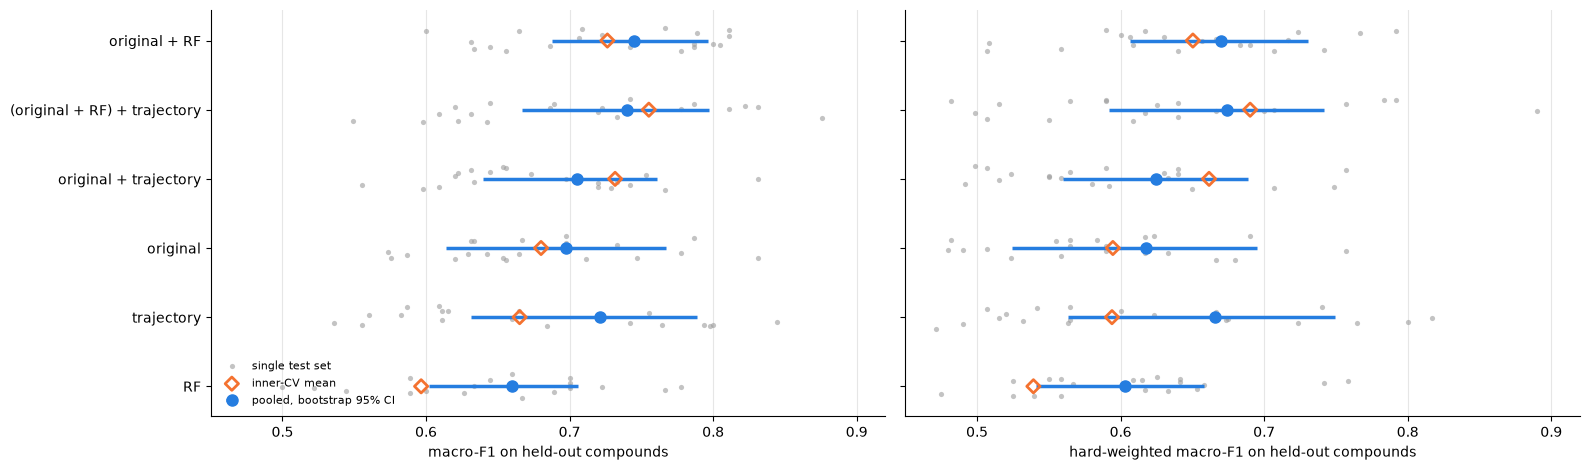

In [8]:
BLUE, ORANGE, AQUA, GREY = "#257de0", "#f47230", "#00b894", "#9c9c9c"
SEQ = LinearSegmentedColormap.from_list("seq", ["#ffffff", "#cce3fd", "#84b9f3", "#338ced", "#1b64be", "#0e3d7e"])
short = [c.replace(" polymerization", "").replace(" inhibitor", "") for c in classes]
order = list(summary.index[::-1])
def tidy(ax):
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", color="#e6e6e6"); ax.set_axisbelow(True)

LABEL = {"macro_F1": "macro-F1", "hard_F1": "hard-weighted macro-F1"}
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), sharey=True)
for ax, (k, cw) in zip(axes, F1S.items()):
    for i, m in enumerate(order):
        v, (lo, hi), pt = per_seed[per_seed.method == m][k], boot[k][m].quantile([.025, .975]), pooled_f1(m, cw)
        ax.scatter(v, i + rng.uniform(-.18, .18, len(v)), s=14, color=GREY, alpha=.6, lw=0, label="single test set" if i == 0 else None)
        ax.errorbar(pt, i, xerr=[[pt - lo], [hi - pt]], fmt="o", ms=8, lw=2.5, color=BLUE,
                    label="pooled, bootstrap 95% CI" if i == 0 else None, zorder=3)
        ax.scatter(per_seed[per_seed.method == m][f"inner_cv_{k}"].mean(), i, marker="D", s=46, facecolor="none",
                   edgecolor=ORANGE, lw=2, label="inner-CV mean" if i == 0 else None, zorder=3)
    ax.set_yticks(range(len(order)), order); ax.set_xlabel(f"{LABEL[k]} on held-out compounds"); ax.set_xlim(0.45, 0.92); tidy(ax)
axes[0].legend(loc="lower left", frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "best_methods_macro_f1.png", dpi=130, bbox_inches="tight"); plt.show()

### Gain over the reference: paired bootstrap distribution

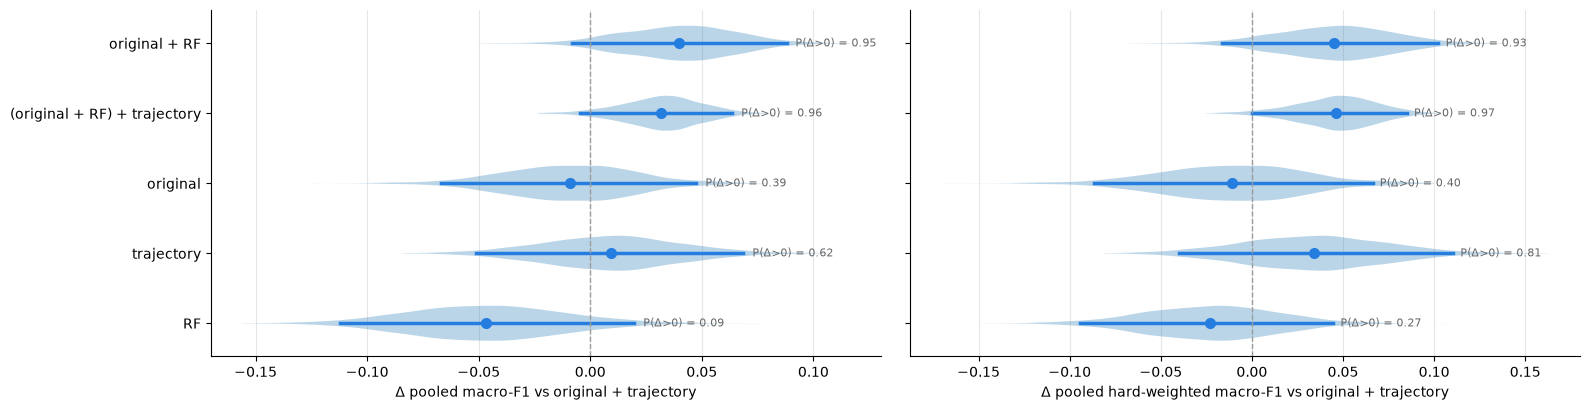

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2), sharey=True)
others = [m for m in order if m != REF]
for ax, k in zip(axes, F1S):
    d = delta[k]
    ax.violinplot([d[m] for m in others], positions=range(len(others)), vert=False, showextrema=False)
    for i, m in enumerate(others):
        lo, hi = d[m].quantile([.025, .975])
        ax.plot([lo, hi], [i, i], color=BLUE, lw=2.5); ax.plot(d[m].mean(), i, "o", color=BLUE, ms=7)
        ax.text(hi + .004, i, f"P(Δ>0) = {(d[m] > 0).mean():.2f}", va="center", fontsize=8, color="#666")
    ax.axvline(0, color=GREY, lw=1, ls="--"); ax.set_yticks(range(len(others)), others)
    ax.set_xlabel(f"Δ pooled {LABEL[k]} vs {REF}"); tidy(ax)
fig.tight_layout(); fig.savefig(FIG / "best_methods_delta_bootstrap.png", dpi=130, bbox_inches="tight"); plt.show()

### Confusion matrices
These pool the held-out predictions of all 20 seeds. Rows are true classes, normalised to recall, and the numbers are percentages (shown when ≥ 5).

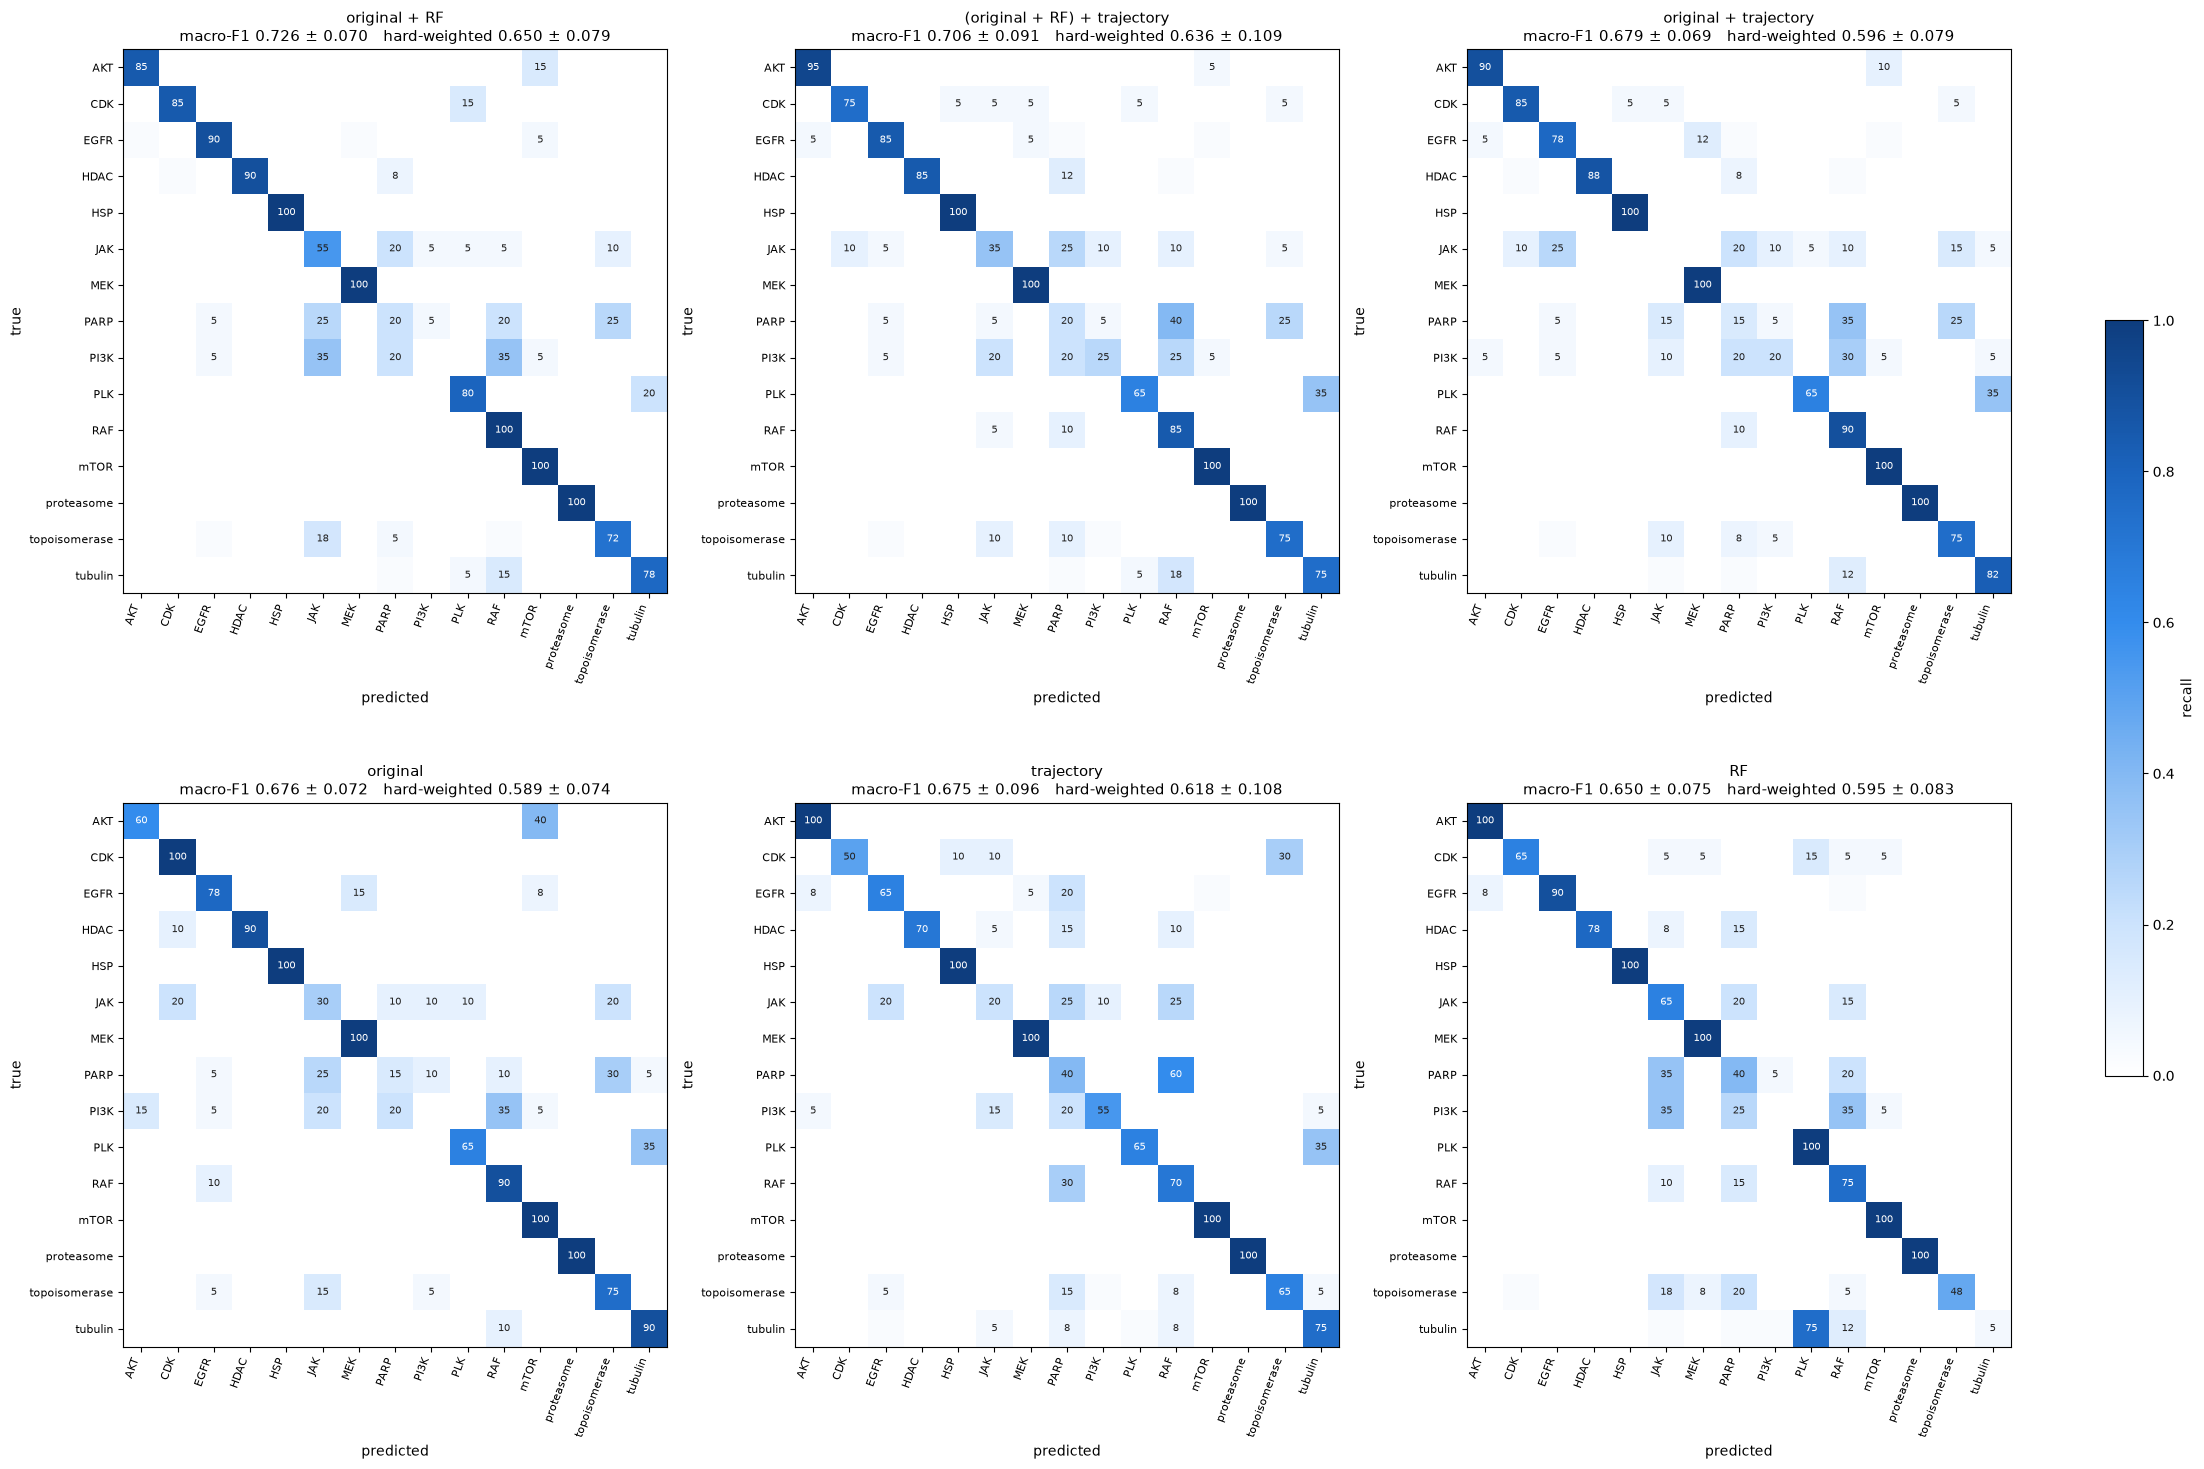

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(22, 15), constrained_layout=True)
for ax, m in zip(axes.flat, summary.index):
    t, P = pooled(m)
    M = np.zeros((K, K)); np.add.at(M, (t, P.argmax(1)), 1); M /= M.sum(1, keepdims=True)
    im = ax.imshow(M, cmap=SEQ, vmin=0, vmax=1)
    for i, j in zip(*np.nonzero(M >= .05)):
        ax.text(j, i, f"{M[i, j] * 100:.0f}", ha="center", va="center", fontsize=7, color="white" if M[i, j] > .55 else "#222")
    ax.set_xticks(range(K), short, rotation=70, ha="right", fontsize=8); ax.set_yticks(range(K), short, fontsize=8)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(f"{m}\nmacro-F1 {summary.loc[m, 'macro_F1 (mean ± SD)']}   hard-weighted {summary.loc[m, 'hard_F1 (mean ± SD)']}", fontsize=11)
fig.colorbar(im, ax=axes, fraction=.02, label="recall")
fig.savefig(FIG / "best_methods_confusion.png", dpi=110, bbox_inches="tight"); plt.show()

### Per-class F1 (pooled over the 20 test sets), hardest classes on the left
Classes marked ×2 are the double-weighted hard classes. The last two columns are the pooled macro-F1 and hard-weighted macro-F1.

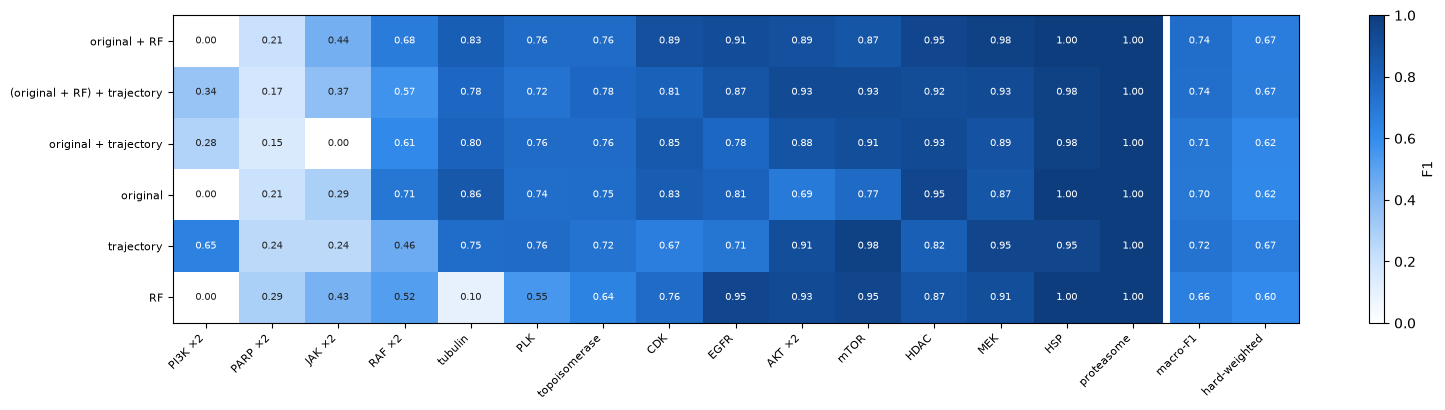

In [11]:
def class_f1(m):
    t, P = pooled(m); tp, nt, npd = counts(t, P.argmax(1)); return 2 * tp / np.maximum(nt + npd, 1)
C = pd.DataFrame({m: class_f1(m) for m in summary.index}, index=[s + (" ×2" if c in HARD else "") for s, c in zip(short, classes)]).T
C = C[C.mean().sort_values().index]
C["macro-F1"], C["hard-weighted"] = [[pooled_f1(m, cw) for m in C.index] for cw in F1S.values()]
fig, ax = plt.subplots(figsize=(16, 4.2))
im = ax.imshow(C.values, cmap=SEQ, vmin=0, vmax=1, aspect="auto")
for (i, j), v in np.ndenumerate(C.values):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > .55 else "#222")
ax.set_xticks(range(C.shape[1]), C.columns, rotation=45, ha="right", fontsize=8); ax.set_yticks(range(len(C)), C.index, fontsize=8)
ax.axvline(K - .5, color="white", lw=5)                                # separates classes from the two summary scores
fig.colorbar(im, ax=ax, label="F1"); fig.tight_layout()
fig.savefig(FIG / "best_methods_per_class_f1.png", dpi=130, bbox_inches="tight"); plt.show()

### Prediction confidence: is the top probability trustworthy?
**Left: reliability diagram** over all 20 test sets. Compounds are binned by top-class probability, and each point is that bin's accuracy (marker area ∝ number of compounds). Points on the diagonal mean "70% confident" really is right 70% of the time. Points above it mean the model is underconfident, and points below it mean overconfident. ECE is the count-weighted mean gap.
**Right: accuracy vs coverage.** Predictions are ranked by confidence, and the curve shows the accuracy of the most confident fraction. Use it to decide how many test calls to trust. A model can be badly calibrated and still rank its predictions well.

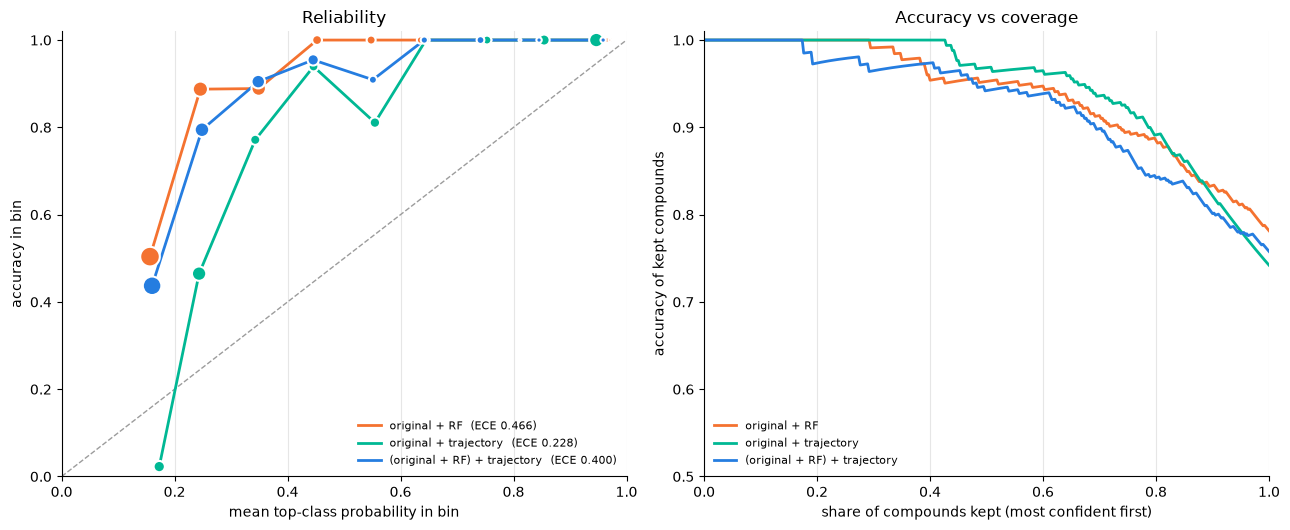

,original + RF,(original + RF) + trajectory,original + trajectory,original,trajectory,RF
ECE,0.466,0.4,0.228,0.185,0.176,0.459


In [12]:
def reliability(m, bins=np.linspace(0, 1, 11)):
    t, P = pooled(m); conf, hit = P.max(1), P.argmax(1) == t
    b = np.clip(np.digitize(conf, bins) - 1, 0, len(bins) - 2)
    d = pd.DataFrame({"b": b, "conf": conf, "hit": hit}).groupby("b").agg(conf=("conf", "mean"), acc=("hit", "mean"), n=("hit", "size"))
    return d, (d.n * (d.acc - d.conf).abs()).sum() / d.n.sum()

ece = pd.Series({m: reliability(m)[1] for m in summary.index}, name="ECE")
fig, (ax, bx) = plt.subplots(1, 2, figsize=(13, 5.4))
ax.plot([0, 1], [0, 1], ls="--", color=GREY, lw=1)
for m, c in [("original + RF", ORANGE), (REF, AQUA), ("(original + RF) + trajectory", BLUE)]:
    d, e = reliability(m)
    ax.plot(d.conf, d.acc, color=c, lw=2, label=f"{m}  (ECE {e:.3f})")
    ax.scatter(d.conf, d.acc, s=d.n * 1.5, color=c, edgecolor="white", lw=1.5, zorder=3)
    t, P = pooled(m); hit = (P.argmax(1) == t)[np.argsort(-P.max(1))]
    bx.plot(np.arange(1, len(hit) + 1) / len(hit), np.cumsum(hit) / np.arange(1, len(hit) + 1), color=c, lw=2, label=m)
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="mean top-class probability in bin", ylabel="accuracy in bin", title="Reliability")
bx.set(xlim=(0, 1), ylim=(0.5, 1.01), xlabel="share of compounds kept (most confident first)", ylabel="accuracy of kept compounds",
       title="Accuracy vs coverage")
ax.legend(frameon=False, fontsize=8, loc="lower right"); bx.legend(frameon=False, fontsize=8, loc="lower left"); tidy(ax); tidy(bx)
fig.tight_layout(); fig.savefig(FIG / "best_methods_reliability.png", dpi=130, bbox_inches="tight"); plt.show()
ece.to_frame().T.round(3)

## 7. Conclusion

**Held-out scores are lower than the earlier CV numbers.** Earlier notebooks reported 0.753 for original + RF and 0.744 for the walkthrough blend. Those scores were tuned and evaluated on the same 86 compounds. With weights chosen on inner folds and scoring on unseen compounds, the pooled values are (hard-weighted = PI3K, PARP, JAK, RAF and AKT counted ×2):

| method | macro-F1 [95% CI] | hard-weighted F1 [95% CI] | Δ macro vs ref | Δ hard-weighted vs ref | w/t/l macro · hard |
|---|---|---|---|---|---|
| **original + RF** | **0.745** [0.687, 0.796] | 0.670 [0.606, 0.731] | +0.040 [−0.008, +0.088] | +0.045 [−0.017, +0.102] | 13/2/5 · 16/2/2 |
| (original + RF) + trajectory | 0.740 [0.667, 0.797] | **0.674** [0.592, 0.742] | +0.032 [−0.005, +0.064] | +0.046 [−0.000, +0.085] | 10/6/4 · 12/6/2 |
| trajectory | 0.721 [0.631, 0.789] | 0.666 [0.563, 0.749] | +0.009 [−0.051, +0.069] | +0.034 [−0.040, +0.110] | 8/1/11 · 11/1/8 |
| original + trajectory (walkthrough blend) | 0.705 [0.640, 0.761] | 0.625 [0.560, 0.688] | reference | reference | — |
| original | 0.698 [0.614, 0.767] | 0.618 [0.524, 0.695] | −0.009 [−0.067, +0.048] | −0.011 [−0.087, +0.066] | 9/5/6 · 6/5/9 |
| RF | 0.660 [0.602, 0.706] | 0.603 [0.541, 0.658] | −0.047 [−0.112, +0.020] | −0.023 [−0.094, +0.045] | 8/0/12 · 9/0/11 |

- **On macro-F1, original + RF is best** (RF weight ≈ 0.8, `min_samples_leaf=24`). It has the highest mean, accuracy and balanced accuracy, and wins 13 of 20 seeds against the walkthrough blend. Its gain is likely but not certain: the 95% CI just touches zero.
- **On hard-weighted F1, original + RF and the 3-way blend tie** (0.670 vs 0.674, well inside each other's CIs). Original + RF wins more seeds (16 vs 12), while the 3-way blend has the tighter CI. The 3-way blend is the closest any method comes to a clear gain over the walkthrough blend (P(Δ>0) = 0.975). Its benefit comes almost entirely from PI3K: F1 0.34 vs 0.00. That costs a little on RAF (0.57 vs 0.68) and on CDK.
- **Trajectory alone matters more on the hard classes than its macro-F1 suggests.** It goes from +0.009 to +0.034 over the reference, because it is the only model that recovers PI3K (0.65).
- **Hard classes remain hard** for every method. Even the best hard-weighted score (0.67) is 0.07 below the plain macro-F1. PARP (≤ 0.29) and JAK (≤ 0.44) are not solved by any method. PARP is mostly called RAF, JAK or topoisomerase.
- **The weights are tuned on plain macro-F1.** If the hard classes are what matters, tune on the hard-weighted F1 in the inner CV. That is a one-word change in `tune`.
- **Confidence.** Every method is **underconfident**: a top probability of 0.2–0.4 is right 80–90% of the time. The RF blends are the worst (ECE 0.40–0.47, log-loss 1.3–1.4) because forest probabilities are flat. Their ranking still works: original + RF gets its most confident ~30% of calls all correct and its top 60% ~95% correct. Use the probabilities to rank calls. If calibrated values are needed, fit a temperature in the inner CV.

Caveat: the 20 test sets re-draw from the same 86 compounds. The CIs cover a different draw of compounds like these, not a shift to a different compound library.